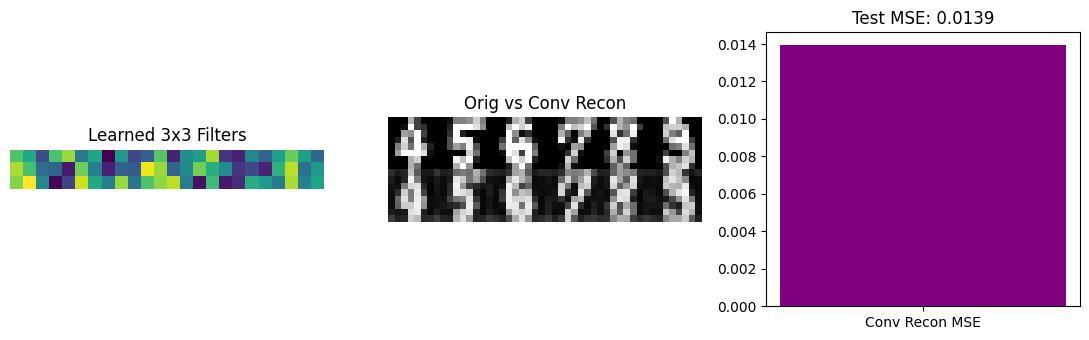

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from tensorflow.keras import layers, models

imgs = (load_digits().images[:500] / 16.0)[..., None]  # (500, 8, 8, 1)
conv_ae = models.Sequential([
    layers.Input(shape=(8, 8, 1)),
    layers.Conv2D(8, (3, 3), padding="same", activation="relu", name="conv_f"),
    layers.Conv2D(1, (3, 3), padding="same", activation="sigmoid")
])
conv_ae.compile(optimizer="adam", loss="mse")
conv_ae.fit(imgs[:400], imgs[:400], epochs=25, batch_size=32, verbose=0)

w = conv_ae.get_layer("conv_f").get_weights()[0]  # (3, 3, 1, 8)
rec = conv_ae.predict(imgs[400:406], verbose=0)[..., 0]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
f_grid = np.hstack([w[:, :, 0, i] for i in range(8)])
axes[0].imshow(f_grid, cmap="viridis"); axes[0].set_title("Learned 3x3 Filters"); axes[0].axis("off")

comp = np.vstack([np.hstack(imgs[400:406, ..., 0]), np.hstack(rec)])
axes[1].imshow(comp, cmap="gray"); axes[1].set_title("Orig vs Conv Recon"); axes[1].axis("off")

mse_val = np.mean((imgs[400:] - conv_ae.predict(imgs[400:], verbose=0)) ** 2)
axes[2].bar(["Conv Recon MSE"], [mse_val], color="purple"); axes[2].set_title(f"Test MSE: {mse_val:.4f}")
plt.tight_layout(); plt.show()